In [207]:
from pathlib import Path
import shutil

import torch
from torch import nn
from torch.utils.data import DataLoader

from torchvision import datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
# print("사용할 장치: ", device)

from pathlib import Path
import shutil

source_dir = Path(r"C:\Users\user\Desktop\dataset\mnist")
raw_dir = Path(r"C:\Users\user\Desktop\dataset\data\MNIST\raw")
raw_dir.mkdir(parents=True, exist_ok=True)

filenames = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]

for filename in filenames:
    source = source_dir / filename
    destination = raw_dir / filename

    # print("확인 중:", source)

    if not source.is_file():
        raise FileNotFoundError(f"원본 파일을 찾을 수 없습니다: {source}")

    shutil.copy2(source, destination)

# print("데이터 파일 준비 완료")


학습 이미지 수: 60000
테스트 이미지 수: 10000
이미지 모양:  torch.Size([64, 1, 28, 28])
정답 모양:  torch.Size([64])


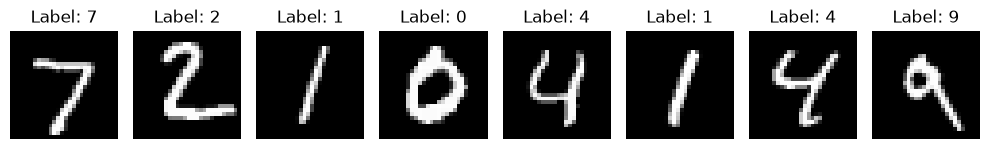

In [208]:
training_data = datasets.MNIST(
    root = r"C:\Users\user\Desktop\dataset\data",
    train = True ,
    download = False,
    transform = ToTensor(),
)

test_data = datasets.MNIST(
    root = r"C:\Users\user\Desktop\dataset\data",
    train = False,
    download = False,
    transform = ToTensor(),
)
print("학습 이미지 수:", len(training_data))
print("테스트 이미지 수:", len(test_data))

batch_size = 64

train_dataloader = DataLoader(
    test_data,
    batch_size = batch_size,
    shuffle = False,
    num_workers = 0,
)

test_dataloader = DataLoader(
    test_data,
    batch_size = batch_size,
    shuffle = False,
    num_workers = 0
)

images, labels = next(iter(train_dataloader))

print("이미지 모양: ", images.shape)
print("정답 모양: ", labels.shape)

plt.figure(figsize=(10, 3))

for i in range(8) :
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i, 0].numpy(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
class CNN(nn.Module) :
    def __init__(self) :
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels = 1,
            out_channels = 16,
            kernel_size = 3,            # 3
            padding = 1,                # 1
        )

        self.conv2 = nn.Conv2d(
            in_channels = 16,
            out_channels = 32,
            kernel_size = 3,            # 3
            padding = 1,                # 1
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size = 3, stride = 2)       # kernel_size = 2, stride = 2       
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 6 * 6, 128)       # 32 * 7 * 7, 128
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x) :
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
    

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
    

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

model = CNN().to(device)



# print(model)

In [210]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.001,)

In [211]:
def train(dataloader, model, loss_fn, optimizer) :
    model.train()

    total_loss = 0.0
    total_count = 0

    for images, labels in dataloader :
        images = images.to(device)
        labels = labels.to(device)

        predictions = model(images)
        loss = loss_fn(predictions, labels)


        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_count += images.size(0)

    average_loss = total_loss / total_count
    print(f"학습 평균 손실: {average_loss : .4f}")

def test(dataloader, model, loss_fn) :
    model.eval()

    total_loss = 0.0
    correct = 0
    total_count = 0

    with torch.no_grad() :
        for images, labels in dataloader :
            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images)
            loss = loss_fn(predictions, labels)

            predicted_labels = predictions.argmax(dim = 1)

            correct += (predicted_labels == labels).sum().item()
            total_loss += loss.item() * images.size(0)
            total_count += images.size(0)

    average_loss = total_loss / total_count
    accuracy = 100 * correct / total_count

    print(f"테스트 평균 손실: {average_loss: .4f}")
    print(f"테스트 정확도: {accuracy: .2f}%")

In [212]:
epochs = 30

for epoch in range(epochs) :
    print(f"\nEpoch {epoch + 1}/{epochs}")
    print("_" *20)

    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

print("\n학습 완료")


Epoch 1/30
____________________
학습 평균 손실:  2.2981
테스트 평균 손실:  2.2960
테스트 정확도:  12.68%

Epoch 2/30
____________________
학습 평균 손실:  2.2940
테스트 평균 손실:  2.2918
테스트 정확도:  14.28%

Epoch 3/30
____________________
학습 평균 손실:  2.2899
테스트 평균 손실:  2.2879
테스트 정확도:  16.15%

Epoch 4/30
____________________
학습 평균 손실:  2.2861
테스트 평균 손실:  2.2841
테스트 정확도:  18.24%

Epoch 5/30
____________________
학습 평균 손실:  2.2822
테스트 평균 손실:  2.2801
테스트 정확도:  20.05%

Epoch 6/30
____________________
학습 평균 손실:  2.2780
테스트 평균 손실:  2.2757
테스트 정확도:  22.72%

Epoch 7/30
____________________
학습 평균 손실:  2.2736
테스트 평균 손실:  2.2712
테스트 정확도:  26.56%

Epoch 8/30
____________________
학습 평균 손실:  2.2689
테스트 평균 손실:  2.2662
테스트 정확도:  31.28%

Epoch 9/30
____________________
학습 평균 손실:  2.2636
테스트 평균 손실:  2.2606
테스트 정확도:  35.31%

Epoch 10/30
____________________
학습 평균 손실:  2.2575
테스트 평균 손실:  2.2541
테스트 정확도:  38.20%

Epoch 11/30
____________________
학습 평균 손실:  2.2505
테스트 평균 손실:  2.2466
테스트 정확도:  39.99%

Epoch 12/30
____________________
학습 평균 손

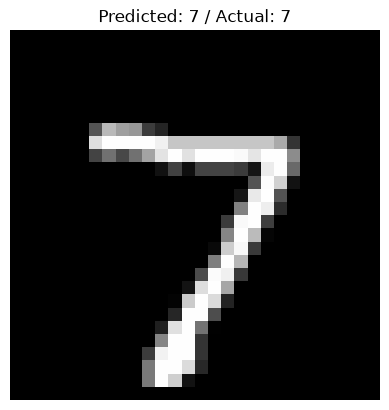

모델의 예측: 7
실제 정답: 7
모델 저장 완료
모델 불러오기 완료
전체 시험 이미지 수: 10000
정답을 맞힌 수: 7458
정답 정확도:  74.58%


In [213]:
model.eval()

image, label = test_data[0]

input_image = image.unsqueeze(0).to(device)

with torch.no_grad() :
    output = model(input_image)
    predicted_label = output.argmax(dim = 1).item()

plt.imshow(image.squeeze(0).numpy(), cmap="gray")
plt.title(f"Predicted: {predicted_label} / Actual: {label}")
plt.axis("off")
plt.show()

print("모델의 예측:", predicted_label)
print("실제 정답:", label)

torch.save(model.state_dict(), "mnist_cnn.pth")
print("모델 저장 완료")

loaded_model = CNN().to(device)

loaded_model.load_state_dict(
    torch.load(
        "mnist_cnn.pth",
        map_location = device,
        weights_only = True,
    )
)

loaded_model.eval()

print("모델 불러오기 완료")

correct = 0
total = 0

loaded_model.eval()

with torch.no_grad() :
    for images, labels in test_dataloader :
        images = images.to(device)
        labels = labels.to(device)

        output = loaded_model(images)
        predicted_label = output.argmax(dim=1)

        correct += (predicted_label == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print("전체 시험 이미지 수:", total)
print("정답을 맞힌 수:", correct)
print(f"정답 정확도: {accuracy: .2f}%")